# PRACTICE 2: PREDICTING PRODUCT SALES
## CHẶNG 1: KHÁM PHÁ DỮ LIỆU BÁN HÀNG TMĐT (EXPLORATORY DATA ANALYSIS)

> **Mục tiêu kỹ thuật:**
> - Khám phá cấu trúc và đánh giá chất lượng bộ dữ liệu thô Amazon Sale Report (128.975 dòng).
> - Phân tích phân phối đơn biến lệch phải của biến mục tiêu `Amount` và lợi ích nén của biến đổi Log1p.
> - Điều tra phân phối đa biến theo ngành hàng, kênh hoàn tất, quét ngoại lai IQR và đúc kết định hướng kỹ thuật cho Chặng 2.


---
## 0. GIỚI THIỆU BỘ DỮ LIỆU AMAZON SALES REPORT
- **Quy mô tập dữ liệu thô:** 128.975 dòng giao dịch thương mại điện tử với 24 cột thuộc tính.
- **Bài toán kinh doanh:** Dự đoán giá trị thực doanh số đơn hàng `Amount` (INR - Rupee Ấn Độ).
- **Nguyên tắc xử lý cốt lõi:** Lọc bỏ đơn hủy, bảo toàn đơn ngoại lai sỉ bằng hàm nén log1p, khử triệt để trùng lặp (Zero Duplicate Leakage).

---
## Mục 1: Khám phá Dữ liệu Tổng quan — Cấu trúc, Chất lượng & Đơn biến (Overview EDA)

### 1.1 Khai báo Thư viện & Thiết lập Môi trường Thực nghiệm
**Mục tiêu:** Cố định hạt giống ngẫu nhiên `RANDOM_SEED = 42` bảo đảm tính tái lập kết quả và thiết lập môi trường phân tích dữ liệu.

In [2]:
import os
import sys
from pathlib import Path
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)

BASE_DIR = Path.cwd().parent if Path.cwd().name in ['scripts', 'notebooks'] else Path.cwd()
if str(BASE_DIR) not in sys.path:
    sys.path.insert(0, str(BASE_DIR))

print(f"✓ Môi trường sẵn sàng. Thư mục gốc: {BASE_DIR}")
images_dir = BASE_DIR / 'docs' / 'images'
images_dir.mkdir(parents=True, exist_ok=True)


✓ Môi trường sẵn sàng. Thư mục gốc: d:\DH_GTVT\NĂM 3\ML\baitap_code_Nhom_3\PRACTICE 2_PREDICTING_PRODUCT_SALES


### 1.2 Khảo sát Cấu trúc & Đánh giá Sơ bộ Chất lượng Dữ liệu Thô
**Mục tiêu:** Nạp tệp dữ liệu thô `Amazon Sale Report.csv`, kiểm tra số lượng giao dịch, số cột thuộc tính và đo lường tỷ lệ dữ liệu khuyết thiếu.

In [3]:
from data.scripts.eda import inspect_data_structure

RAW_CSV = BASE_DIR / 'data' / 'raw' / 'Amazon Sale Report.csv'
df_raw = pd.read_csv(RAW_CSV, low_memory=False)

struct_info = inspect_data_structure(df_raw)
print(f"1. Quy mô dữ liệu thô: {struct_info['n_rows']:,} dòng, {struct_info['n_cols']} cột thuộc tính")
print(f"2. Số dòng trùng lặp thô toàn bộ bảng: {struct_info['n_duplicates']:,} dòng")

# Bảng khảo sát cấu trúc toàn bộ 24 cột dữ liệu
summary_cols_df = pd.DataFrame({
    'Cột dữ liệu': struct_info['columns'],
    'Kiểu dữ liệu (dtype)': [struct_info['dtypes'][c] for c in struct_info['columns']],
    'Số dòng khuyết': [struct_info['missing_counts'][c] for c in struct_info['columns']],
    'Tỷ lệ khuyết (%)': [struct_info['missing_pct'][c] for c in struct_info['columns']]
})
print("\n3. Bảng khảo sát chi tiết 24 cột dữ liệu & tỷ lệ khuyết thiếu:")
display(summary_cols_df)

print("\n4. Xem trước 5 dòng dữ liệu thô đầu tiên (head):")
display(df_raw.head(5))

1. Quy mô dữ liệu thô: 128,975 dòng, 24 cột thuộc tính
2. Số dòng trùng lặp thô toàn bộ bảng: 0 dòng

3. Bảng khảo sát chi tiết 24 cột dữ liệu & tỷ lệ khuyết thiếu:


,Cột dữ liệu,Kiểu dữ liệu (dtype),Số dòng khuyết,Tỷ lệ khuyết (%)
0,index,int64,0,0.00
1,Order ID,object,0,0.00
2,Date,object,0,0.00
3,Status,object,0,0.00
4,Fulfilment,object,0,0.00
5,Sales Channel,object,0,0.00
6,ship-service-level,object,0,0.00
7,Style,object,0,0.00
8,SKU,object,0,0.00
9,Category,object,0,0.00



4. Xem trước 5 dòng dữ liệu thô đầu tiên (head):


,index,Order ID,Date,Status,Fulfilment,Sales Channel,ship-service-level,Style,SKU,Category,...,currency,Amount,ship-city,ship-state,ship-postal-code,ship-country,promotion-ids,B2B,fulfilled-by,Unnamed: 22
0,0,405-8078784-5731545,04-30-22,Cancelled,Merchant,Amazon.in,Standard,SET389,SET389-KR-NP-S,Set,...,INR,647.62,MUMBAI,MAHARASHTRA,400081.0,IN,NaN,False,Easy Ship,NaN
1,1,171-9198151-1101146,04-30-22,Shipped - Delivered to Buyer,Merchant,Amazon.in,Standard,JNE3781,JNE3781-KR-XXXL,kurta,...,INR,406.00,BENGALURU,KARNATAKA,560085.0,IN,Amazon PLCC Free-Financing Universal Merchant ...,False,Easy Ship,NaN
2,2,404-0687676-7273146,04-30-22,Shipped,Amazon,Amazon.in,Expedited,JNE3371,JNE3371-KR-XL,kurta,...,INR,329.00,NAVI MUMBAI,MAHARASHTRA,410210.0,IN,IN Core Free Shipping 2015/04/08 23-48-5-108,True,NaN,NaN
3,3,403-9615377-8133951,04-30-22,Cancelled,Merchant,Amazon.in,Standard,J0341,J0341-DR-L,Western Dress,...,INR,753.33,PUDUCHERRY,PUDUCHERRY,605008.0,IN,NaN,False,Easy Ship,NaN
4,4,407-1069790-7240320,04-30-22,Shipped,Amazon,Amazon.in,Expedited,JNE3671,JNE3671-TU-XXXL,Top,...,INR,574.00,CHENNAI,TAMIL NADU,600073.0,IN,NaN,False,NaN,NaN


### 1.3 Phân tích Đơn biến Biến Mục tiêu (Amount) & Lợi ích của Biến đổi Log
**Mục tiêu:** Đo lường các chỉ số thống kê mô tả, khảo sát độ lệch phải cực đoan của biến Amount và kiểm chứng hiệu quả nén phương sai bằng hàm $\ln(1 + \text{Amount})$.

• Trung bình doanh số (Mean): 648.56 INR
• Trung vị doanh số (Median): 605.00 INR
• Độ lệch (Skewness): 0.89 (Lệch phải cực đoan)
• Độ lệch sau Log (Skewness Log): 0.15 (Đã nén về phân phối đối xứng chuẩn mực)


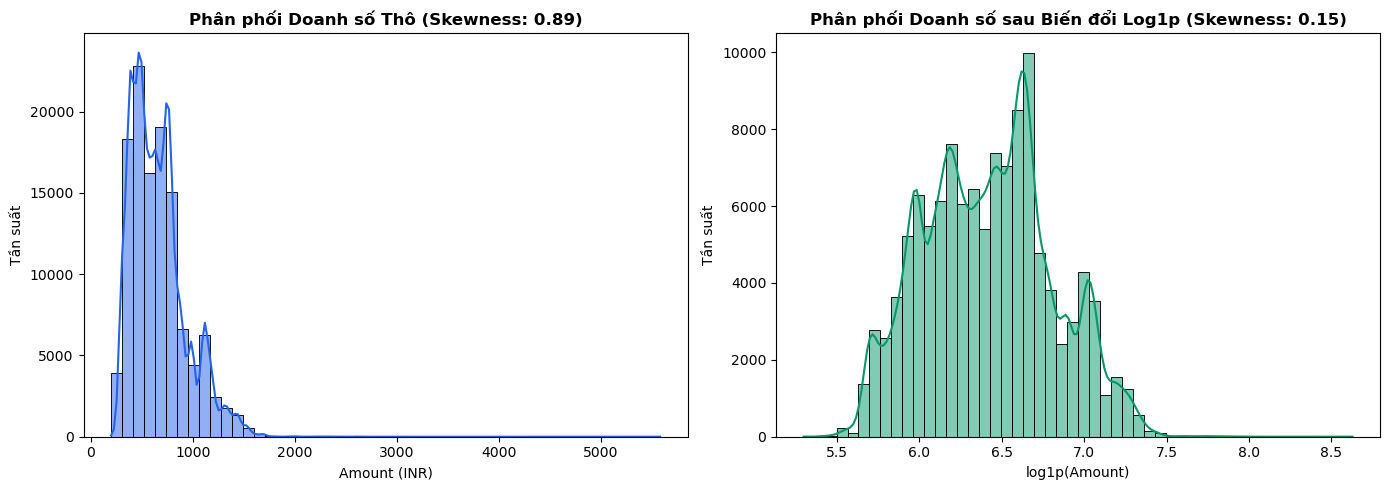

In [4]:
from data.scripts.eda import get_univariate_stats

stats_raw = get_univariate_stats(df_raw, col='Amount')
print(f"• Trung bình doanh số (Mean): {stats_raw['mean']:.2f} INR")
print(f"• Trung vị doanh số (Median): {stats_raw['median']:.2f} INR")
print(f"• Độ lệch (Skewness): {stats_raw['skewness']:.2f} (Lệch phải cực đoan)")

amount_valid = df_raw['Amount'].dropna()
amount_valid = amount_valid[amount_valid > 0]
amount_log = np.log1p(amount_valid)
skew_log = float(pd.Series(amount_log).skew())
print(f"• Độ lệch sau Log (Skewness Log): {skew_log:.2f} (Đã nén về phân phối đối xứng chuẩn mực)")

# Trực quan hóa đối chiếu phân phối trước và sau biến đổi Log1p
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.histplot(amount_valid, bins=50, kde=True, ax=axes[0], color='#2563eb')
axes[0].set_title(f'Phân phối Doanh số Thô (Skewness: {stats_raw["skewness"]:.2f})', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Amount (INR)')
axes[0].set_ylabel('Tần suất')

sns.histplot(amount_log, bins=50, kde=True, ax=axes[1], color='#059669')
axes[1].set_title(f'Phân phối Doanh số sau Biến đổi Log1p (Skewness: {skew_log:.2f})', fontsize=12, fontweight='bold')
axes[1].set_xlabel('log1p(Amount)')
axes[1].set_ylabel('Tần suất')

plt.tight_layout()
plt.savefig(images_dir / 'eda_01_amount_distribution.png', dpi=300, bbox_inches='tight')
plt.show()


---
## Mục 2: Khám phá Dữ liệu Chuyên sâu — Đa biến, Ngoại lai & Đúc kết định hướng (In-depth EDA)

### 2.1 Phân tích Đa biến: Doanh số theo Ngành hàng & Kênh Hoàn tất (Fulfilment)
**Mục tiêu:** Khảo sát sự phân hóa doanh số qua từng ngành hàng sản phẩm (Category) và kênh thực hiện đơn hàng (Fulfilment) để nhận diện các phân khúc giá then chốt.

--- 1. BẢNG DOANH SỐ THEO NGÀNH HÀNG (TOP CATEGORIES) ---


,Category,count,mean,median,std,total,share_pct
0,Set,47042,833.39,788.00,293.35,39204124.03,49.88
1,kurta,46717,455.93,435.00,148.86,21299546.70,27.10
2,Western Dress,14704,762.79,744.00,167.73,11216072.69,14.27
3,Top,10165,526.10,519.05,149.06,5347792.30,6.80
4,Ethnic Dress,1093,723.90,837.00,264.33,791217.66,1.01
5,Blouse,881,520.33,545.00,175.19,458408.18,0.58
6,Bottom,420,358.73,345.00,116.95,150667.98,0.19
7,Saree,155,799.57,791.00,202.92,123933.76,0.16
8,Dupatta,3,305.00,305.00,0.00,915.00,0.00



--- 2. BẢNG DOANH SỐ THEO KÊNH HOÀN TẤT (FULFILMENT) ---


,Fulfilment,count,mean,median,std,total,share_pct
0,Amazon,83639,649.48,599.0,281.76,54322151.0,69.12
1,Merchant,37541,646.51,629.0,279.99,24270527.3,30.88


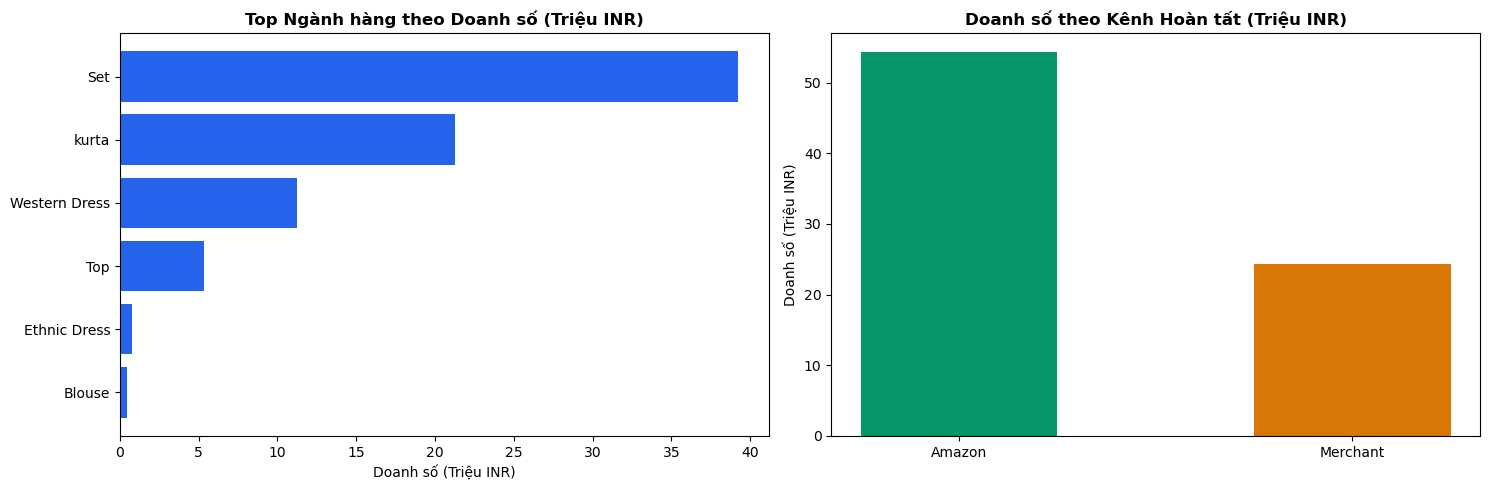

In [5]:
from data.scripts.eda import get_bivariate_analysis

df_clean_subset = df_raw.dropna(subset=['Amount', 'Category', 'Fulfilment'])
bivariate_res = get_bivariate_analysis(df_clean_subset, target='Amount', cat_cols=['Category', 'Fulfilment'])
bivariate_cat = bivariate_res['category_stats']
bivariate_ful = bivariate_res['fulfilment_stats']

print("--- 1. BẢNG DOANH SỐ THEO NGÀNH HÀNG (TOP CATEGORIES) ---")
display(bivariate_cat.head(10))

print("\n--- 2. BẢNG DOANH SỐ THEO KÊNH HOÀN TẤT (FULFILMENT) ---")
display(bivariate_ful)

# Trực quan hóa doanh số theo Top ngành hàng và Kênh hoàn tất
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
top_cats = bivariate_cat.head(6)
axes[0].barh(top_cats['Category'][::-1], top_cats['total'][::-1] / 1e6, color='#2563eb')
axes[0].set_title('Top Ngành hàng theo Doanh số (Triệu INR)', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Doanh số (Triệu INR)')

axes[1].bar(bivariate_ful['Fulfilment'], bivariate_ful['total'] / 1e6, color=['#059669', '#d97706'], width=0.5)
axes[1].set_title('Doanh số theo Kênh Hoàn tất (Triệu INR)', fontsize=12, fontweight='bold')
axes[1].set_ylabel('Doanh số (Triệu INR)')

plt.tight_layout()
plt.savefig(images_dir / 'eda_02_bivariate_category_fulfilment.png', dpi=300, bbox_inches='tight')
plt.show()


### 2.2 Quét Ngoại lai Doanh số theo Khoảng Tứ phân vị (IQR)
**Mục tiêu:** Xác định ngưỡng ngoại lai thống kê bằng quy tắc IQR và đề xuất giải pháp xử lý bảo toàn thông tin đơn hàng số lượng lớn (B2B).

• Ngưỡng ngoại lai trên (Upper Bound): 1296.50 INR
• Số lượng đơn hàng vượt ngưỡng: 3,600 đơn (2.97%)


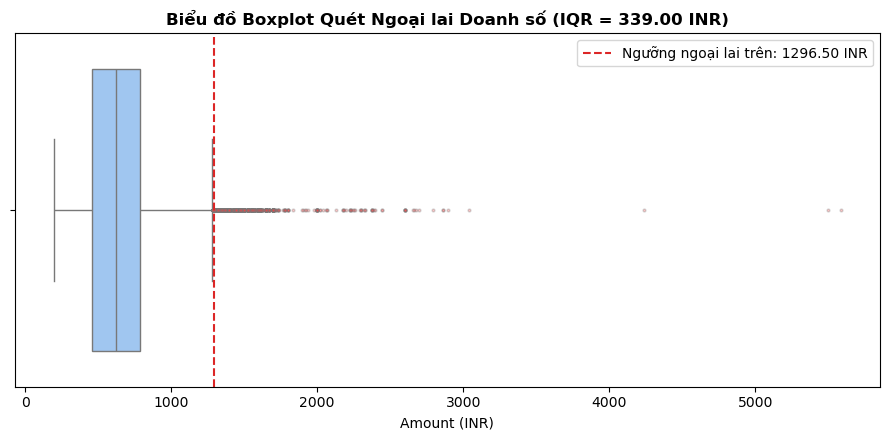

In [6]:
from data.scripts.eda import detect_iqr_outliers

outliers_info = detect_iqr_outliers(df_raw['Amount'])
print(f"• Ngưỡng ngoại lai trên (Upper Bound): {outliers_info['upper_bound']:.2f} INR")
print(f"• Số lượng đơn hàng vượt ngưỡng: {outliers_info['n_outliers']:,} đơn ({outliers_info['outlier_pct']:.2f}%)")

# Trực quan hóa quét ngoại lai bằng biểu đồ Boxplot IQR
plt.figure(figsize=(9, 4.5))
sns.boxplot(x=amount_valid, color='#93c5fd', flierprops={'marker': 'o', 'markersize': 2, 'alpha': 0.3, 'markerfacecolor': '#ef4444'})
plt.axvline(outliers_info['upper_bound'], color='#dc2626', linestyle='--', linewidth=1.5, label=f"Ngưỡng ngoại lai trên: {outliers_info['upper_bound']:.2f} INR")
plt.title(f'Biểu đồ Boxplot Quét Ngoại lai Doanh số (IQR = {outliers_info["iqr"]:.2f} INR)', fontsize=12, fontweight='bold')
plt.xlabel('Amount (INR)')
plt.legend()
plt.tight_layout()
plt.savefig(images_dir / 'eda_03_outliers_boxplot.png', dpi=300, bbox_inches='tight')
plt.show()


### 2.3 Tổng kết EDA & Định hướng Kế hoạch Tiền xử lý (Actionable Insights)
**Mục tiêu:** Tổng hợp các phát hiện then chốt từ EDA và chốt định hướng kỹ thuật cho khâu làm sạch dữ liệu.

In [7]:
print("=== TỔNG KẾT EDA & KẾ HOẠCH HÀNH ĐỘNG KỸ THUẬT ===")
print("1. Lọc đơn hủy (Cancelled) & đơn lỗi (Amount <= 0, Qty <= 0).")
print("2. Điền khuyết thiếu: promotion-ids ('No_Promotion'), Courier Status ('Unshipped'), ship-state (mode).")
print("3. Bảo toàn đơn hàng giá trị cao bằng hàm nén log1p thay vì xóa cứng.")
print("4. Loại bỏ các cột định danh (index, Order ID) và cột phương sai 0 (currency, Sales Channel).")
print("5. Khử triệt để trùng lặp giao dịch (Zero Duplicate Leakage).")

=== TỔNG KẾT EDA & KẾ HOẠCH HÀNH ĐỘNG KỸ THUẬT ===
1. Lọc đơn hủy (Cancelled) & đơn lỗi (Amount <= 0, Qty <= 0).
2. Điền khuyết thiếu: promotion-ids ('No_Promotion'), Courier Status ('Unshipped'), ship-state (mode).
3. Bảo toàn đơn hàng giá trị cao bằng hàm nén log1p thay vì xóa cứng.
4. Loại bỏ các cột định danh (index, Order ID) và cột phương sai 0 (currency, Sales Channel).
5. Khử triệt để trùng lặp giao dịch (Zero Duplicate Leakage).
